# Group 7 — 5-fold dataset + video-3 tiles for Roboflow (data only)

Runs on a normal CPU runtime (no GPU, no training), about 10 minutes. It makes:

1. **`DATA_FOR_TEAM_5FOLD/`** — the 5-fold dataset (`sg_dataset_5fold.zip`) + the video-1/2 frame files + `MANIFEST.sha256` + `verify_download.py`, checked after Drive finishes syncing. Send this folder to the team.
2. **`ROBOFLOW_V3/`** — 20 tiles from video 3 to label in Roboflow (`images.zip`), plus the classical labeller's masks for the same tiles (for scoring later; not for upload).

**Nothing existing is changed.** The videos are only read from `DRIVE_DIR`. Everything is written to the new folder `OUT_ROOT` (`MyDrive/SGTracking_5FOLD`); your `SGTracking/content` and `SGTracking_LOVO` folders are not touched.

**5 folds, grouped by tile position.** Each frame is a 4 × 4 grid of 256 × 256 tiles, and a grid position shows the same cells in every frame. All frames of a position therefore stay in one fold: fold *j*'s test set = its positions; train/val = the other positions (val = last 15 % of each video's frames, for early stopping only). Video 3 is never in any fold — it is the final, human-labelled test.

In [15]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
from google.colab import drive
drive.mount('/content/drive')
!pip -q install imageio-ffmpeg

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
# ======================= CONFIG =======================
DRIVE_DIR = '/content/drive/MyDrive/SGTracking/content'   # videos live here - READ ONLY
OUT_ROOT  = '/content/drive/MyDrive/SGTracking_5FOLD'     # NEW folder - everything is written here
VIDEOS = {'v1': '0 to 1hrs_DR_chan00.avi',                 # training pool for the 5 folds
          'v2': '1 to 2 hrs_DR_chan00.avi'}
SKIP_FIRST = {'v1': 1, 'v2': 1, 'v3': 0}                   # frame 0 of v1 is before granules form
V3_PATTERN = '1_to_1h42m*.avi'                             # held-out video 3 (only for Roboflow tiles)
N_FOLDS, VAL_FRAC = 5, 0.15
RF_FRAMES, RF_PER_FRAME = 5, 4                             # 5 frames x 4 tiles = 20 tiles to label
# ======================================================
import os, glob, shutil, time
import imageio_ffmpeg
for old in [DRIVE_DIR, '/content/drive/MyDrive/SGTracking_LOVO']:
    assert not os.path.abspath(OUT_ROOT).startswith(os.path.abspath(old)), 'OUT_ROOT must be a new folder outside ' + old
CACHE    = os.path.join(OUT_ROOT, 'cache')
TEAM_DIR = os.path.join(OUT_ROOT, 'DATA_FOR_TEAM_5FOLD')
RF_DIR   = os.path.join(OUT_ROOT, 'ROBOFLOW_V3')
os.makedirs(CACHE, exist_ok=True)

PATHS = {}
for v, f in VIDEOS.items():
    p = os.path.join(DRIVE_DIR, f)
    assert os.path.exists(p), 'missing video: ' + p
    PATHS[v] = p
hits = sorted(glob.glob(os.path.join(DRIVE_DIR, V3_PATTERN)))
if hits:
    PATHS['v3'] = hits[0]
else:
    print('Video 3 not found with pattern', repr(V3_PATTERN), '- the .avi files in DRIVE_DIR are:')
    for f in sorted(glob.glob(os.path.join(DRIVE_DIR, '*.avi'))): print('   ', os.path.basename(f))
    print('Set V3_PATTERN to its name to get the Roboflow tiles; the 5-fold dataset is made either way.')
for v, p in PATHS.items():
    n, _ = imageio_ffmpeg.count_frames_and_secs(p)
    print('%s: %-30s %7.1f MB  %3d frames' % (v, os.path.basename(p), os.path.getsize(p) / 1e6, n))
print('\nreading videos from', DRIVE_DIR, '\nwriting everything to', OUT_ROOT)

v1: 0 to 1hrs_DR_chan00.avi           66.1 MB   21 frames
v2: 1 to 2 hrs_DR_chan00.avi         270.5 MB   86 frames
v3: 1_to_1h42m_DR_chan01.avi         465.6 MB  148 frames

reading videos from /content/drive/MyDrive/SGTracking/content 
writing everything to /content/drive/MyDrive/SGTracking_5FOLD


### Code modules (written to `sgtrack/`)

In [4]:
!mkdir -p sgtrack

In [5]:
%%writefile sgtrack/__init__.py

Writing sgtrack/__init__.py


In [6]:
%%writefile sgtrack/preprocess.py
"""Stage 1 - loading, photobleach correction, stabilisation (registration) and optical flow.

Every function works on a stack shaped (T, H, W) of float32 images in [0, 1].
"""
import numpy as np
import cv2
from skimage.registration import phase_cross_correlation


# ----------------------------------------------------------------------------- loading
def load_video(path, channel=None, min_frames=3):
    """Read an AVI/MP4 into a (T, H, W) float32 stack in [0, 1] (ffmpeg backend).

    The microscopy videos are pseudo-coloured red, so by default we take the per-pixel max
    over RGB. Raises a clear error if the file decodes to fewer than `min_frames` frames -
    the usual cause is an incomplete upload / Google Drive sync (a truncated raw AVI simply
    decodes to fewer frames without any error).
    """
    import os
    import imageio.v2 as iio2
    frames = np.asarray(iio2.mimread(path, format="FFMPEG", memtest=False))
    if frames.ndim == 4:
        frames = frames[..., channel] if channel is not None else frames.max(-1)
    if len(frames) < min_frames:
        raise ValueError(
            "%s decoded to only %d frame(s) (file size %.1f MB). The file is probably "
            "incomplete - re-upload it to Drive, wait until the upload finishes, then delete "
            "the cache/*_pre.npz files and re-run." % (os.path.basename(path), len(frames),
                                                         os.path.getsize(path) / 1e6))
    return frames.astype(np.float32) / 255.0


# ----------------------------------------------------------------------------- photobleaching
def correct_photobleaching(stack, fg_percentile=75):
    """Exponential-fit photobleaching correction.

    Photobleaching makes the signal decay roughly as exp(-k t); a fixed threshold would then
    lose granules in late frames. We measure each frame's foreground level (median of the
    non-saturated pixels above the `fg_percentile`-th percentile), fit log(level) = a - k t,
    and multiply frame t by exp(k t).

    If the fit shows no decay (k <= 0, i.e. the signal *rises*, e.g. because granules are
    forming) we do not touch the data - dimming a real biological increase would be wrong.
    Returns (corrected_stack, gains, levels).
    """
    levels = []
    for f in stack:
        thr = np.percentile(f, fg_percentile)
        sel = f[(f > thr) & (f < 0.999)]
        levels.append(np.median(sel) if sel.size else thr)
    levels = np.array(levels) + 1e-6
    t = np.arange(len(stack))
    ok = np.isfinite(levels) & (levels > 1e-5)
    if ok.sum() >= 3:
        slope, _ = np.polyfit(t[ok], np.log(levels[ok]), 1)
        k = max(-slope, 0.0)
    else:                      # too few usable frames to fit a decay -> no correction
        k = 0.0
    gains = np.exp(k * t)
    out = np.clip(stack * gains[:, None, None], 0, 1).astype(np.float32)
    return out, gains, levels


def denoise(stack, sigma=1.0):
    """Light Gaussian smoothing to suppress shot noise before registration / thresholding."""
    k = int(2 * round(3 * sigma) + 1)
    return np.stack([cv2.GaussianBlur(f, (k, k), sigma) for f in stack])


# ----------------------------------------------------------------------------- registration
def register_stack(stack, mode="euclidean", downsample=2, ecc_iters=200):
    """Stabilise the video so every frame is in the coordinate system of frame 0.

    1. Phase correlation gives a robust frame-to-frame translation (global drift).
    2. ECC (enhanced correlation coefficient) refines it, warm-started from step 1.
       mode="euclidean" (default) = rigid translation + rotation, which is what stage drift
       physically is. mode="affine" also allows scale/shear, but because cells themselves
       grow/move, a free affine slowly drifts in scale when chained over many frames
       (we measured ~13 % over 21 frames), so it is only offered as an option.
    3. Frame-to-frame transforms are chained so frame t is mapped onto frame 0.

    Returns (registered_stack, transforms) with transforms[t] a 3x3 matrix mapping
    frame-t pixel coordinates to frame-0 coordinates.
    """
    T, H, W = stack.shape
    motion = {"affine": cv2.MOTION_AFFINE, "euclidean": cv2.MOTION_EUCLIDEAN,
              "translation": cv2.MOTION_TRANSLATION}[mode]
    criteria = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, ecc_iters, 1e-5)
    small = [cv2.resize(f, (W // downsample, H // downsample), interpolation=cv2.INTER_AREA)
             for f in stack]

    cum = [np.eye(3, dtype=np.float64)]
    for t in range(1, T):
        prev, cur = small[t - 1], small[t]
        shift, _, _ = phase_cross_correlation(prev, cur, upsample_factor=10, normalization=None)
        warp = np.array([[1, 0, -shift[1]], [0, 1, -shift[0]]], dtype=np.float32)
        try:
            _, warp = cv2.findTransformECC(prev, cur, warp, motion, criteria, None, 5)
        except cv2.error:
            pass  # ECC failed to converge - keep the phase-correlation translation
        # ECC warp maps prev coords -> cur coords; we want cur -> prev (inverse)
        M = np.vstack([warp.astype(np.float64), [0, 0, 1]])
        M[:2, 2] *= downsample
        cum.append(cum[-1] @ np.linalg.inv(M))

    reg = np.empty_like(stack)
    for t in range(T):
        reg[t] = cv2.warpAffine(stack[t], cum[t][:2].astype(np.float32), (W, H),
                                flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0)
    return reg, np.stack(cum)


def valid_region(transforms, shape):
    """Pixels that are inside the field of view in *every* registered frame."""
    H, W = shape
    mask = np.ones((H, W), np.uint8)
    for M in transforms:
        m = cv2.warpAffine(np.ones((H, W), np.uint8), M[:2].astype(np.float32), (W, H),
                           flags=cv2.INTER_NEAREST, borderValue=0)
        mask &= m
    return mask.astype(bool)


# ----------------------------------------------------------------------------- optical flow
def optical_flow_magnitude(stack):
    """Per-pixel optical displacement (px / frame) between consecutive frames (Farneback).

    Returns an array (T, H, W); frame 0 re-uses the 0->1 flow so shapes line up with `stack`.
    """
    u8 = (np.clip(stack, 0, 1) * 255).astype(np.uint8)
    mags = []
    for t in range(1, len(u8)):
        flow = cv2.calcOpticalFlowFarneback(u8[t - 1], u8[t], None,
                                            pyr_scale=0.5, levels=3, winsize=15,
                                            iterations=3, poly_n=5, poly_sigma=1.2, flags=0)
        mags.append(np.linalg.norm(flow, axis=-1))
    mags.insert(0, mags[0])
    return np.stack(mags).astype(np.float32)

Writing sgtrack/preprocess.py


In [7]:
%%writefile sgtrack/pseudolabel.py
"""Stage 2 - bivariate (intensity x optical displacement) histogram, cell masks and granule
pseudo-masks. These pseudo-masks are the training targets for YOLO and U-Net (no manual labels).
"""
import numpy as np
import cv2
from scipy import ndimage as ndi
from sklearn.mixture import GaussianMixture
from skimage import measure, morphology, segmentation, feature


def _remove_small(x, min_size):
    """Remove objects with area < min_size (works on bool masks and label images, any skimage version)."""
    lab = measure.label(x) if x.dtype == bool else x
    counts = np.bincount(lab.ravel())
    keep = counts >= min_size
    keep[0] = False
    out = keep[lab]
    return out if x.dtype == bool else np.where(out, lab, 0)


# ----------------------------------------------------------------------------- features
def _features(I, D):
    """Feature transform used for the mixture model.
    sqrt(I) spreads out the dark end where background lives; log1p(D) compresses the long
    tail of optical-flow noise."""
    return np.stack([np.sqrt(np.clip(I, 0, 1)), np.log1p(D)], -1)


class BivariateCellClassifier:
    """Gaussian mixture on per-pixel (intensity, optical displacement).

    Why 3 components and not 2: optical flow is exactly ~0 in flat dark regions but noisy in
    textured dark regions, so with 2 components the "background" Gaussian collapses onto
    D ~ 0 and any dark pixel with flow noise is called "cell" (the model separates moving vs
    still, not cell vs background). With 3 components the mixture finds
    (i) empty background (I ~ 0, D ~ 0), (ii) dark, noisy pixels (low I, small random D) and
    (iii) cell pixels (high I, coherent D). Components (i)+(ii) = background.
    The `n_bg` lowest-intensity components are background, the rest are cell.
    `bounds()` gives P(cell) on an (intensity, displacement) grid for drawing the bound.
    """

    def __init__(self, n_components=3, n_bg=2, n_samples=200_000, seed=0):
        self.n_components, self.n_bg = n_components, n_bg
        self.n_samples = n_samples
        self.seed = seed

    def fit(self, I_stack, D_stack):
        rng = np.random.default_rng(self.seed)
        I, D = I_stack.ravel(), D_stack.ravel()
        idx = rng.choice(I.size, size=min(self.n_samples, I.size), replace=False)
        X = _features(I[idx], D[idx])
        self.gmm = GaussianMixture(self.n_components, covariance_type="full",
                                   random_state=self.seed).fit(X)
        order = np.argsort(self.gmm.means_[:, 0])
        self.cell_comps = order[self.n_bg:]
        self.sample = (I[idx], D[idx])
        # intensity floor = the bound for a pixel at rest (D = 0)
        grid = np.linspace(0, 1, 2001)
        p0 = self._gmm_prob(grid, np.zeros_like(grid))
        self.i_floor = float(grid[np.argmax(p0 > 0.5)]) if (p0 > 0.5).any() else 0.0
        return self

    def _gmm_prob(self, I, D):
        X = _features(np.ravel(I), np.ravel(D))
        return self.gmm.predict_proba(X)[:, self.cell_comps].sum(1).reshape(np.shape(I))

    def prob_cell(self, I, D):
        """P(cell) = GMM posterior x soft intensity floor. The floor encodes the physical
        constraint that displacement alone (optical-flow noise in dark areas) cannot make a
        pixel a cell pixel - it must also be brighter than resting background."""
        gate = 1 / (1 + np.exp(-(np.asarray(I) - self.i_floor) / 0.005))
        return self._gmm_prob(I, D) * gate

    def bounds(self, i_max=1.0, d_max=10.0, n=300):
        ii, dd = np.meshgrid(np.linspace(0, i_max, n), np.linspace(0, d_max, n))
        return ii, dd, self.prob_cell(ii, dd)


def cell_mask(prob, min_area=500, smooth=3):
    """Clean the per-pixel P(cell) map into a binary cell mask (semantic segmentation)."""
    m = cv2.GaussianBlur(prob.astype(np.float32), (0, 0), smooth) > 0.5
    m = _remove_small(m, min_area)
    m = ndi.binary_fill_holes(m)          # nuclei are dark holes in a cytoplasmic stain
    return m


def cell_instances(I, mask, sigma=10, min_distance=30, min_area=800):
    """Split the cell mask into individual cells (instance segmentation of cells).

    Touching cells form large clumps, so a distance-transform watershed under-segments them.
    Instead each cell's cytoplasm forms its own brightness "dome": we take log-intensity
    (so dim cells get a dome too), close the dark nucleus holes, smooth with a Gaussian
    (sigma ~ cell radius / 3), seed the watershed at its local maxima and flood inside `mask`.
    Returns an int label image (0 = background).
    """
    L = np.log(I.astype(np.float32) + 0.02)
    L = cv2.morphologyEx(L, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15)))
    S = cv2.GaussianBlur(L, (0, 0), sigma)
    peaks = feature.peak_local_max(S, min_distance=min_distance, labels=mask.astype(int),
                                   exclude_border=False)
    markers = np.zeros(mask.shape, np.int32)
    markers[tuple(peaks.T)] = np.arange(1, len(peaks) + 1)
    lab = segmentation.watershed(-S, markers, mask=mask)
    lab = _remove_small(lab, min_area)
    lab, _, _ = segmentation.relabel_sequential(lab)
    return lab


def propagate_cells(I, mask, prev, sigma=10, core_radius=6, min_distance=30, min_area=800,
                    next_id=None, new_min_area=1500):
    """Temporally consistent cell instances: seed frame t's watershed with the eroded cores
    of frame t-1's cells (so a cell keeps its ID), plus new seeds for cell regions that no
    previous core covers (cells entering the field / newly bright); new cells smaller than
    `new_min_area` are discarded. Returns (labels, next_id)."""
    L = np.log(I.astype(np.float32) + 0.02)
    L = cv2.morphologyEx(L, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15)))
    S = cv2.GaussianBlur(L, (0, 0), sigma)
    se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * core_radius + 1,) * 2)
    markers = np.zeros(mask.shape, np.int32)
    for l in np.unique(prev):
        if l == 0:
            continue
        core = cv2.erode((prev == l).astype(np.uint8), se).astype(bool) & mask
        if core.sum() >= 20:
            markers[core] = l
    next_id = int(prev.max()) + 1 if next_id is None else next_id
    uncovered = mask & ~ndi.binary_dilation(markers > 0, iterations=min_distance)
    if uncovered.any():
        peaks = feature.peak_local_max(np.where(uncovered, S, S.min()), min_distance=min_distance,
                                       labels=measure.label(uncovered), exclude_border=False)
        for py, px in peaks:
            markers[py, px] = next_id
            next_id += 1
    first_new = int(prev.max()) + 1 if prev.max() else 1
    lab = segmentation.watershed(-S, markers, mask=mask)
    lab = _remove_small(lab, min_area)
    # a *new* cell must be a substantial region, otherwise flickering dim patches keep
    # spawning short-lived IDs
    counts = np.bincount(lab.ravel())
    small_new = np.where((np.arange(len(counts)) >= first_new) & (counts < new_min_area))[0]
    small_new = small_new[np.isin(small_new, markers[markers > 0])]
    if len(small_new):
        lab[np.isin(lab, small_new)] = 0
    return lab, next_id


# ----------------------------------------------------------------------------- granules
def granule_score(I, tophat_radius=8, eps=0.05, smooth=1.0, cells=None, fill_sigma=15):
    """Local-contrast granule score = (I - local cytoplasm level) / local cytoplasm level.

    A single global threshold fails because cell brightness varies ~10x across the field
    (bright cells' texture passes, faint granules in dim cells are missed). Dividing the
    top-hat (granule excess brightness) by the morphological opening (local cytoplasm
    level) makes the score a *relative* brightness, comparable across cells.

    Edge fix: next to dark background the opening drops to ~0, which made cell rims look
    like granules. If `cells` is given, pixels outside cells are first filled with the
    nearby cytoplasm level (normalised convolution: G*(I*M) / G*M) so the background
    estimate is not dragged down at cell borders.
    """
    I = cv2.GaussianBlur(I.astype(np.float32), (0, 0), smooth)
    if cells is not None:
        M = cells.astype(np.float32)
        num = cv2.GaussianBlur(I * M, (0, 0), fill_sigma)
        den = cv2.GaussianBlur(M, (0, 0), fill_sigma)
        fill = np.where(den > 1e-3, num / np.maximum(den, 1e-3), 0)
        I = np.where(cells, I, fill).astype(np.float32)
    se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * tophat_radius + 1,) * 2)
    bg = cv2.morphologyEx(I, cv2.MORPH_OPEN, se)
    bg = cv2.GaussianBlur(bg, (0, 0), tophat_radius / 2)
    return (I - bg) / (bg + eps)


def granule_mask(I, cells, tophat_radius=8, k=4.0, min_area=4, max_area=400, sat_area=400,
                 min_ratio=0.3, max_ecc=0.95, min_solidity=0.7):
    """Pseudo-mask of stress granules inside cells.

    Granules are small bright puncta on top of a diffuse cytoplasmic signal, so we
    1. compute a local-contrast score (see `granule_score`),
    2. threshold at median + k*MAD of the score *inside cells* (robust statistics, so the
       granules themselves do not inflate the threshold) and also require the granule to
       be at least `min_ratio` (25 %) brighter than its surroundings,
    3. keep components with min_area <= area <= max_area that are roughly round
       (eccentricity <= max_ecc and solidity >= min_solidity for objects > 20 px; this
       rejects thin bright streaks along cell edges),
    4. ignore large saturated blobs (whole over-exposed cells are not granules).
    """
    th = granule_score(I, tophat_radius, cells=cells)
    vals = th[cells]
    if vals.size == 0:
        return np.zeros_like(cells)
    med = np.median(vals)
    mad = np.median(np.abs(vals - med)) * 1.4826 + 1e-6
    m = (th > max(med + k * mad, min_ratio)) & cells
    m = ndi.binary_opening(m, structure=morphology.disk(1))
    lab = measure.label(m)
    sat = (I >= 0.999)
    sat_lab = measure.label(_remove_small(sat, sat_area))
    keep = np.zeros(lab.max() + 1, bool)
    for r in measure.regionprops(lab):
        if not (min_area <= r.area <= max_area):
            continue
        if r.area > 20 and (r.eccentricity > max_ecc or r.solidity < min_solidity):
            continue
        keep[r.label] = True
    out = keep[lab]
    out &= ~(sat_lab > 0)
    return out


def blobness(I, sigmas=(1.5, 2.5, 3.5)):
    """Scale-normalised Hessian blob response.

    For a bright blob both Hessian eigenvalues are strongly negative; for a ridge (cell rim,
    membrane) one eigenvalue is ~0. Using B = max_sigma sigma^2 * max(0, -lambda_max), where
    lambda_max is the *larger* eigenvalue, therefore responds to round granules and ignores
    thin bright lines. Returns (B, best_sigma)."""
    from skimage.feature import hessian_matrix, hessian_matrix_eigvals
    best = np.zeros(I.shape, np.float32)
    best_s = np.zeros(I.shape, np.float32)
    for s in sigmas:
        H = hessian_matrix(I, sigma=s, order="rc", use_gaussian_derivatives=False)
        l1, l2 = hessian_matrix_eigvals(H)          # l1 >= l2
        b = (s ** 2) * np.maximum(0, -l1)
        upd = b > best
        best[upd], best_s[upd] = b[upd], s
    return best, best_s


def granule_instances_blob(I, cells, k=4.0, min_ratio=0.5, rel_level=0.5, min_area=4,
                           max_area=400, min_distance=3, tophat_radius=8, sat_area=400,
                           max_ecc=0.95, min_solidity=0.7, max_radius=12):
    """Granule *instance* pseudo-labels via blob detection + half-max region growing.

    1. local background level `bg` (edge-filled morphological opening, see granule_score);
    2. relative blobness  B / (bg + eps)  -> seeds = local maxima above median + k*MAD (inside
       cells) whose local contrast (granule_score) is >= `min_ratio`;
    3. each seed is grown by watershed on the smoothed image, but only over pixels brighter than
       bg + rel_level * (peak - bg)  (half-maximum contour -> stable size across frames) and
       within 2.5*sigma+2 px of the seed (sigma = best blob scale), so it cannot leak along rims;
    4. size / shape / saturation filters as in `granule_mask`.
    Returns an int32 label image.
    """
    Is = cv2.GaussianBlur(I.astype(np.float32), (0, 0), 1.0)
    score = granule_score(I, tophat_radius, cells=cells)
    eps = 0.05
    bg = (Is - eps * score) / (1 + score)   # invert score = (I - bg) / (bg + eps)
    B, Bsig = blobness(Is)
    Brel = B / (np.maximum(bg, 0) + eps)
    vals = Brel[cells & (Brel > 0)]   # most pixels have zero blobness -> use positive part only
    if vals.size == 0:
        return np.zeros(I.shape, np.int32)
    med = np.median(vals)
    mad = np.median(np.abs(vals - med)) * 1.4826 + 1e-6
    thr = med + k * mad
    peaks = feature.peak_local_max(Brel, min_distance=min_distance, threshold_abs=thr,
                                   labels=cells.astype(np.int32), exclude_border=False)
    peaks = np.array([p for p in peaks if score[p[0], p[1]] >= min_ratio]).reshape(-1, 2)
    if len(peaks) == 0:
        return np.zeros(I.shape, np.int32)
    markers = np.zeros(I.shape, np.int32)
    markers[tuple(peaks.T)] = np.arange(1, len(peaks) + 1)
    # per-seed half-max level
    pk_I = Is[tuple(peaks.T)]
    pk_bg = np.maximum(bg[tuple(peaks.T)], 0)
    level = np.concatenate([[np.inf], pk_bg + rel_level * (pk_I - pk_bg)])
    candidate = cells & (score > 0)
    lab = segmentation.watershed(-Is, markers, mask=candidate)
    lab = np.where(Is >= level[lab], lab, 0)
    # cap growth at a radius tied to the blob scale (stops leaking along dim membrane rims)
    radius = np.concatenate([[0], np.minimum(max_radius, 2.5 * Bsig[tuple(peaks.T)] + 2)])
    sy = np.concatenate([[0], peaks[:, 0]]); sx = np.concatenate([[0], peaks[:, 1]])
    yy, xx = np.indices(I.shape)
    lab = np.where(np.hypot(yy - sy[lab], xx - sx[lab]) <= radius[lab], lab, 0)
    # keep only the connected piece that contains each seed
    cc = measure.label(lab > 0, connectivity=1)
    seed_cc = np.zeros(len(peaks) + 1, np.int64)
    ok = lab[tuple(peaks.T)] == np.arange(1, len(peaks) + 1)
    seed_cc[1:] = np.where(ok, cc[tuple(peaks.T)], -1)
    out = np.where((lab > 0) & (cc == seed_cc[lab]), lab, 0)
    # filters
    sat_lab = measure.label(_remove_small(I >= 0.999, sat_area))
    final = np.zeros_like(out)
    n = 0
    for r in measure.regionprops(out):
        if not (min_area <= r.area <= max_area):
            continue
        if r.area > 20 and (r.eccentricity > max_ecc or r.solidity < min_solidity):
            continue
        cy, cx = map(int, r.centroid)
        if sat_lab[cy, cx]:
            continue
        n += 1
        final[tuple(r.coords.T)] = n
    return final


def granule_instances(gmask, split=True):
    """Label granules; touching granules are split with a small watershed on the distance map."""
    lab = measure.label(gmask)
    if not split:
        return lab
    dist = ndi.distance_transform_edt(gmask)
    peaks = feature.peak_local_max(dist, min_distance=2, labels=lab, exclude_border=False)
    markers = np.zeros(gmask.shape, np.int32)
    markers[tuple(peaks.T)] = np.arange(1, len(peaks) + 1)
    return segmentation.watershed(-dist, markers, mask=gmask)

Writing sgtrack/pseudolabel.py


In [8]:
%%writefile sgtrack/pipeline.py
"""Glue code: run a whole stage over a video and cache the results to .npz files."""
import os
import numpy as np
from . import preprocess as P
from . import pseudolabel as PL


# ----------------------------------------------------------------------------- safe cache I/O
def load_npz_checked(path, keys=None):
    """Load an .npz completely (every array is read, so the zip CRC of each one is checked).
    Returns a dict, or None if the file is missing, truncated/corrupt, or lacks `keys`.
    A bad file is renamed to *.corrupt so it is rebuilt instead of crashing the run."""
    if not os.path.exists(path):
        return None
    try:
        z = np.load(path)
        out = {k: z[k] for k in z.files}
        if keys is not None and set(keys) - set(out):
            raise KeyError("missing arrays: %s" % sorted(set(keys) - set(out)))
        return out
    except Exception as e:
        bad = path + ".corrupt"
        print("[cache] %s is unreadable (%s: %s) -> moved to %s, rebuilding"
              % (os.path.basename(path), type(e).__name__, str(e)[:80], os.path.basename(bad)))
        os.replace(path, bad)
        return None


def save_npz_checked(path, **arrays):
    """Write to local disk first, copy to the destination (e.g. Google Drive), then re-read the
    destination completely. Writing a large .npz straight onto Drive can leave a truncated file
    if the sync is interrupted - this is what damaged v2_pre.npz."""
    import shutil
    import tempfile
    fd, tmp = tempfile.mkstemp(suffix=".npz")
    os.close(fd)
    try:
        np.savez_compressed(tmp, **arrays)
        shutil.copyfile(tmp, path + ".partial")
        os.replace(path + ".partial", path)
    finally:
        os.remove(tmp)
    chk = load_npz_checked(path, keys=arrays.keys())
    if chk is None:
        raise IOError("could not verify %s after writing" % path)
    print("[cache] saved and verified %s (%.1f MB)" % (os.path.basename(path), os.path.getsize(path) / 1e6))


PRE_KEYS = ("reg", "flow", "T", "valid", "gains", "levels")
PL_KEYS = ("cells", "granules")


def preprocess_video(path, cache, register_mode="euclidean", sigma=1.0):
    """load -> photobleach correction -> denoise -> register -> optical flow. Cached."""
    cached = load_npz_checked(cache, PRE_KEYS)
    if cached is not None:
        return cached
    raw = P.load_video(path)
    corr, gains, levels = P.correct_photobleaching(raw)
    den = P.denoise(corr, sigma)
    reg, T = P.register_stack(den, mode=register_mode)
    valid = P.valid_region(T, reg.shape[1:])
    flow = P.optical_flow_magnitude(reg)
    out = dict(reg=reg.astype(np.float16), flow=flow.astype(np.float16), T=T, valid=valid,
               gains=gains, levels=levels)
    save_npz_checked(cache, **out)
    return out


def pseudolabel_video(pre, cache, frames=None, clf=None, granule_kw=None, cell_kw=None):
    """Bivariate-histogram cell masks + granule pseudo-masks for every frame. Cached.

    Returns dict with cells (T,H,W uint16 cell instances), granules (T,H,W uint16 granule
    instances) and the fitted BivariateCellClassifier (not cached; refit if needed)."""
    reg = pre["reg"].astype(np.float32)
    flow = pre["flow"].astype(np.float32)
    frames = list(range(len(reg))) if frames is None else list(frames)
    if clf is None:
        clf = PL.BivariateCellClassifier().fit(reg[frames], flow[frames])
    cached = load_npz_checked(cache, PL_KEYS)
    if cached is not None:
        return dict(cells=cached["cells"], granules=cached["granules"], clf=clf)
    granule_kw, cell_kw = granule_kw or {}, cell_kw or {}
    T, H, W = reg.shape
    cells = np.zeros((T, H, W), np.uint16)
    gran = np.zeros((T, H, W), np.uint16)
    prev, next_id = None, None
    for t in frames:
        cm = PL.cell_mask(clf.prob_cell(reg[t], flow[t])) & pre["valid"]
        if prev is None:   # first frame: independent segmentation; later: propagate IDs
            cells[t] = PL.cell_instances(reg[t], cm, **cell_kw)
            next_id = int(cells[t].max()) + 1
        else:
            cells[t], next_id = PL.propagate_cells(reg[t], cm, prev, next_id=next_id)
        prev = cells[t].astype(np.int32)
        gran[t] = PL.granule_instances_blob(reg[t], cm, **granule_kw)
    save_npz_checked(cache, cells=cells, granules=gran)
    return dict(cells=cells, granules=gran, clf=clf)


def track_video(labels, reg, cells=None, frames=None, frame_interval=1.0, max_dist=12,
                max_gap=3, event_kw=None, tracker_kw=None):
    """Granule tracking + events + cell assignment for one video.

    labels : (T,H,W) granule instance labels (model predictions or pseudo-labels)
    cells  : (T,H,W) cell instance labels (optional) -> granules get a persistent cell id
    Returns dict(tracks=DataFrame, events=DataFrame (filtered), raw_events=DataFrame,
                 cells=list of cell-tracked label images, per_cell=DataFrame counts).
    """
    import pandas as pd
    from . import tracking as TR
    frames = list(range(len(labels))) if frames is None else list(frames)
    cell_tr = None
    if cells is not None:   # IDs already consistent (propagate_cells); IoU matching as a safety net
        cell_tr = TR.track_cells([cells[f].astype(np.int32) for f in frames])
    dets = []
    for k, f in enumerate(frames):
        dets.append(TR.detections_from_labels(labels[f].astype(np.int32), f,
                                              reg[f].astype(np.float32),
                                              None if cell_tr is None else cell_tr[k]))
    trk = TR.GranuleTracker(max_dist=max_dist, max_gap=max_gap, **(tracker_kw or {}))
    df, raw = trk.run(dets, frames)
    ev = TR.filter_events(df, raw, **(event_kw or {}))
    cent = None
    if cell_tr is not None:
        from skimage import measure
        cent = {(f, r.label): r.centroid for k, f in enumerate(frames)
                for r in measure.regionprops(cell_tr[k])}
    df = TR.add_kinematics(df, frame_interval, cent)
    per_cell = None
    if cell_tr is not None:
        per_cell = (df[df.cell > 0].groupby(["frame", "cell"]).size()
                    .rename("n_granules").reset_index())
    return dict(tracks=df, events=ev, raw_events=raw, cells=cell_tr, per_cell=per_cell)

Writing sgtrack/pipeline.py


In [9]:
%%writefile sgtrack/share.py
"""Leave-one-video-out (LOVO) labelled dataset + checksummed team package.

Dataset layout written by `export_lovo_dataset` (all PNG, 256x256 tiles):

    sg_dataset/
      fold_test_v1/                 <- one folder per video held out
        train/  val/  test/
          images/       <name>.png  uint8 grayscale registered frame tile
          masks/        <name>.png  uint8 binary granule mask (0 / 255)
          instances/    <name>.png  uint16 granule instance labels (0 = background)
          cells/        <name>.png  uint16 cell instance labels
          labels_yolo/  <name>.txt  YOLO boxes (class 0 = granule)
      fold_test_v2/ ...
      to_label/        <name>.png   tiles for manual annotation (Roboflow)
      to_label_pseudo/ <name>.png   their pseudo-masks, for comparison
      tiles.csv  README.md
  <name> = <video>_t<frame>_y<row>_x<col>

Fold "test_vK": test = every tile of video K. Train / val come only from the OTHER videos;
val = the last `val_frac` of each training video's frames (a time block, used only for early
stopping / model selection). No frame of the test video is ever in train or val.
"""
import os
import json
import hashlib
import shutil
import zipfile
import numpy as np
import pandas as pd
import cv2
from skimage import measure, segmentation


SUBDIRS = ("images", "masks", "instances", "cells", "labels_yolo")


def _yolo_lines(inst, tile):
    out = []
    for r in measure.regionprops(inst):
        y0, x0, y1, x1 = r.bbox
        out.append("0 %.6f %.6f %.6f %.6f" % ((x0 + x1) / 2 / tile, (y0 + y1) / 2 / tile,
                                              (x1 - x0) / tile, (y1 - y0) / tile))
    return out


def lovo_roles(frames_by_video, val_frac=0.15):
    """{fold: {video: {frame: 'train'|'val'|'test'}}} for leave-one-video-out."""
    roles = {}
    for test_v in frames_by_video:
        fold = {}
        for v, frames in frames_by_video.items():
            frames = list(frames)
            if v == test_v:
                fold[v] = {f: "test" for f in frames}
            else:
                k = max(1, int(round(len(frames) * val_frac)))
                fold[v] = {f: ("val" if i >= len(frames) - k else "train") for i, f in enumerate(frames)}
        roles["test_" + test_v] = fold
    return roles


def export_lovo_dataset(pre, plb, frames_by_video, out_dir, tile=256, min_valid=0.9,
                        keep_empty=0.2, val_frac=0.15, n_to_label=8, seed=0):
    """Cut every video into tiles once, then lay them out in one folder per LOVO fold."""
    rng = np.random.default_rng(seed)
    if os.path.exists(out_dir):
        shutil.rmtree(out_dir)
    stash = os.path.join(out_dir, "_tiles")
    rows = []
    for v, frames in frames_by_video.items():
        reg, G, C, valid = pre[v]["reg"], plb[v]["granules"], plb[v]["cells"], pre[v]["valid"]
        H, W = reg.shape[1:]
        for sub in SUBDIRS:
            os.makedirs(os.path.join(stash, v, sub), exist_ok=True)
        for f in frames:
            for y in range(0, H - tile + 1, tile):
                for x in range(0, W - tile + 1, tile):
                    if valid[y:y + tile, x:x + tile].mean() < min_valid:
                        continue
                    inst, _, _ = segmentation.relabel_sequential(G[f, y:y + tile, x:x + tile].astype(np.int32))
                    n = int(inst.max())
                    if n == 0 and rng.random() > keep_empty:
                        continue
                    name = "%s_t%03d_y%04d_x%04d" % (v, f, y, x)
                    img = (np.clip(reg[f, y:y + tile, x:x + tile].astype(np.float32), 0, 1) * 255).round().astype(np.uint8)
                    c, _, _ = segmentation.relabel_sequential(C[f, y:y + tile, x:x + tile].astype(np.int32))
                    d = os.path.join(stash, v)
                    cv2.imwrite(os.path.join(d, "images", name + ".png"), img)
                    cv2.imwrite(os.path.join(d, "masks", name + ".png"), ((inst > 0) * 255).astype(np.uint8))
                    cv2.imwrite(os.path.join(d, "instances", name + ".png"), inst.astype(np.uint16))
                    cv2.imwrite(os.path.join(d, "cells", name + ".png"), c.astype(np.uint16))
                    with open(os.path.join(d, "labels_yolo", name + ".txt"), "w") as fh:
                        fh.write("\n".join(_yolo_lines(inst, tile)))
                    rows.append(dict(name=name, video=v, frame=f, y=y, x=x, n_granules=n,
                                     granule_px=int((inst > 0).sum()), n_cells=int(c.max())))
    df = pd.DataFrame(rows)

    roles = lovo_roles(frames_by_video, val_frac)
    for fold, fr in roles.items():
        col = "role_" + fold
        df[col] = [fr[v][f] for v, f in zip(df.video, df.frame)]
        for role in ("train", "val", "test"):
            for sub in SUBDIRS:
                os.makedirs(os.path.join(out_dir, "fold_" + fold, role, sub), exist_ok=True)
        for name, v, role in zip(df.name, df.video, df[col]):
            for sub in SUBDIRS:
                ext = ".txt" if sub == "labels_yolo" else ".png"
                shutil.copyfile(os.path.join(stash, v, sub, name + ext),
                                os.path.join(out_dir, "fold_" + fold, role, sub, name + ext))

    # tiles for manual labelling: spread evenly over the videos, only tiles with granules
    lab, ps = os.path.join(out_dir, "to_label"), os.path.join(out_dir, "to_label_pseudo")
    os.makedirs(lab); os.makedirs(ps)
    vids = list(frames_by_video)
    per = {v: n_to_label // len(vids) + (1 if i < n_to_label % len(vids) else 0) for i, v in enumerate(vids)}
    picked = []
    for v in vids:
        cand = df[(df.video == v) & (df.n_granules > 0)]
        if len(cand):
            picked += list(cand.name.iloc[rng.choice(len(cand), min(per[v], len(cand)), replace=False)])
    for name in picked:
        v = name.split("_")[0]
        shutil.copyfile(os.path.join(stash, v, "images", name + ".png"), os.path.join(lab, name + ".png"))
        shutil.copyfile(os.path.join(stash, v, "masks", name + ".png"), os.path.join(ps, name + ".png"))
    df["to_label"] = df.name.isin(set(picked))
    shutil.rmtree(stash)

    df.to_csv(os.path.join(out_dir, "tiles.csv"), index=False)
    _write_readme(df, roles, out_dir, tile, val_frac)
    return df


def fold_summary(df):
    """Tiles / granules per fold and role."""
    out = []
    for col in [c for c in df.columns if c.startswith("role_")]:
        g = df.groupby(col).agg(tiles=("name", "size"), granules=("n_granules", "sum"))
        for role, r in g.iterrows():
            vids = sorted(df[df[col] == role].video.unique())
            out.append(dict(fold=col[5:], role=role, videos="+".join(vids), tiles=int(r.tiles), granules=int(r.granules)))
    return pd.DataFrame(out)


def _write_readme(df, roles, out_dir, tile, val_frac):
    txt = ["# Stress-granule labelled dataset (Group 7) - leave-one-video-out", "",
           "Tiles of %d x %d px from registered, denoised confocal frames. Labels are pseudo-labels" % (tile, tile),
           "(bivariate-histogram cell masks + Hessian-blob granule masks). Manual ground truth for",
           "`to_label/` is added separately (Roboflow).", "",
           "## Folds",
           "One folder per video held out (`fold_test_<video>`): test = all tiles of that video;",
           "train/val = the other videos, val = last %d%% of each training video's frames (time block," % round(val_frac * 100),
           "for early stopping only). The test video never appears in train or val.", "",
           fold_summary(df).to_string(index=False), "",
           "## Files per tile",
           "images/ (uint8), masks/ (0/255 binary granules), instances/ (uint16 granule ids),",
           "cells/ (uint16 cell ids), labels_yolo/ (class 0 boxes, normalised xywh).",
           "tiles.csv: one row per tile with its role in every fold (columns role_test_<video>).", ""]
    with open(os.path.join(out_dir, "README.md"), "w") as fh:
        fh.write("\n".join(txt))


# ============================================================================ grouped k-fold
def cut_tiles(pre, plb, frames_by_video, stash, tile=256, min_valid=0.9, keep_empty=0.2, seed=0):
    """Cut every frame of every video into tiles once; write them under stash/<video>/<sub>/."""
    rng = np.random.default_rng(seed)
    rows = []
    for v, frames in frames_by_video.items():
        reg, G, C, valid = pre[v]["reg"], plb[v]["granules"], plb[v]["cells"], pre[v]["valid"]
        H, W = reg.shape[1:]
        for sub in SUBDIRS:
            os.makedirs(os.path.join(stash, v, sub), exist_ok=True)
        for f in frames:
            for y in range(0, H - tile + 1, tile):
                for x in range(0, W - tile + 1, tile):
                    if valid[y:y + tile, x:x + tile].mean() < min_valid:
                        continue
                    inst, _, _ = segmentation.relabel_sequential(G[f, y:y + tile, x:x + tile].astype(np.int32))
                    n = int(inst.max())
                    if n == 0 and rng.random() > keep_empty:
                        continue
                    name = "%s_t%03d_y%04d_x%04d" % (v, f, y, x)
                    img = (np.clip(reg[f, y:y + tile, x:x + tile].astype(np.float32), 0, 1) * 255).round().astype(np.uint8)
                    c, _, _ = segmentation.relabel_sequential(C[f, y:y + tile, x:x + tile].astype(np.int32))
                    d = os.path.join(stash, v)
                    cv2.imwrite(os.path.join(d, "images", name + ".png"), img)
                    cv2.imwrite(os.path.join(d, "masks", name + ".png"), ((inst > 0) * 255).astype(np.uint8))
                    cv2.imwrite(os.path.join(d, "instances", name + ".png"), inst.astype(np.uint16))
                    cv2.imwrite(os.path.join(d, "cells", name + ".png"), c.astype(np.uint16))
                    with open(os.path.join(d, "labels_yolo", name + ".txt"), "w") as fh:
                        fh.write("\n".join(_yolo_lines(inst, tile)))
                    rows.append(dict(name=name, video=v, frame=f, y=y, x=x, n_granules=n,
                                     granule_px=int((inst > 0).sum()), n_cells=int(c.max())))
    return pd.DataFrame(rows)


def assign_position_folds(df, k=5, seed=0):
    """Deal the (video, y, x) tile positions into k folds with about equal granule counts.
    A position shows the same cells in every frame, so all its frames stay in one fold."""
    rng = np.random.default_rng(seed)
    g = df.groupby(["video", "y", "x"]).n_granules.sum().reset_index(name="n")
    g = g.iloc[rng.permutation(len(g))].sort_values("n", ascending=False, kind="stable")
    load = np.zeros(k)
    fold = {}
    for _, r in g.iterrows():                      # biggest group -> lightest fold
        j = int(np.argmin(load))
        fold[(r.video, r.y, r.x)] = j + 1           # folds are numbered 1..k
        load[j] += r.n
    return np.array([fold[(v, y, x)] for v, y, x in zip(df.video, df.y, df.x)])


def export_grouped_kfold(pre, plb, frames_by_video, out_dir, k=5, val_frac=0.15, tile=256,
                         min_valid=0.9, keep_empty=0.2, seed=0):
    """k-fold dataset grouped by tile position, one folder per fold:
        fold_<j>/test  = all tiles of the positions in fold j
        fold_<j>/train, val = the other positions; val = last `val_frac` of each video's frames
                              (a time block, for early stopping only)
    No position (= no set of cells) is ever in both train/val and test of the same fold."""
    if os.path.exists(out_dir):
        shutil.rmtree(out_dir)
    stash = os.path.join(out_dir, "_tiles")
    df = cut_tiles(pre, plb, frames_by_video, stash, tile, min_valid, keep_empty, seed)
    df["fold"] = assign_position_folds(df, k, seed)
    last = {}
    for v, frames in frames_by_video.items():
        frames = list(frames)
        n_val = max(1, int(round(len(frames) * val_frac)))
        last[v] = set(frames[-n_val:])
    for j in range(1, k + 1):
        col = "role_fold_%d" % j
        df[col] = ["test" if fo == j else ("val" if f in last[v] else "train")
                   for fo, v, f in zip(df.fold, df.video, df.frame)]
        for role in ("train", "val", "test"):
            for sub in SUBDIRS:
                os.makedirs(os.path.join(out_dir, "fold_%d" % j, role, sub), exist_ok=True)
        for name, v, role in zip(df.name, df.video, df[col]):
            for sub in SUBDIRS:
                ext = ".txt" if sub == "labels_yolo" else ".png"
                shutil.copyfile(os.path.join(stash, v, sub, name + ext),
                                os.path.join(out_dir, "fold_%d" % j, role, sub, name + ext))
    shutil.rmtree(stash)
    df.to_csv(os.path.join(out_dir, "tiles.csv"), index=False)
    summ = kfold_summary(df, k)
    txt = ["# Stress-granule labelled dataset (Group 7) - %d-fold, grouped by tile position" % k, "",
           "Tiles of %d x %d px from registered, denoised frames of %s. Labels are pseudo-labels" % (tile, tile, " and ".join(frames_by_video)),
           "(bivariate-histogram cell masks + Hessian-blob granule masks).", "",
           "Each frame is a 4 x 4 grid of tiles; a grid position shows the same cells in every frame, so all",
           "frames of a position are in the same fold. fold_<j>/test = the positions of fold j; train/val = all",
           "other positions, val = last %d%% of each video's frames (early stopping only)." % round(val_frac * 100),
           "Final test: human-labelled video-3 tiles, shared separately.", "",
           summ.to_string(index=False), "",
           "Files per tile: images/ (uint8), masks/ (0/255 granules), instances/ (uint16 granule ids),",
           "cells/ (uint16 cell ids), labels_yolo/ (class 0 boxes). tiles.csv: fold and role_fold_<j> per tile.", ""]
    with open(os.path.join(out_dir, "README.md"), "w") as fh:
        fh.write("\n".join(txt))
    return df


def kfold_summary(df, k):
    out = []
    for j in range(1, k + 1):
        col = "role_fold_%d" % j
        for role in ("train", "val", "test"):
            d = df[df[col] == role]
            out.append(dict(fold=j, role=role, tiles=len(d), granules=int(d.n_granules.sum()),
                            positions=len(d.groupby(["video", "y", "x"]))))
    return pd.DataFrame(out)


# ============================================================================ Roboflow tiles (held-out video)
def export_label_tiles(pre, plb, video, frames, out_dir, n_frames=5, per_frame=4, tile=256,
                       min_valid=0.9, seed=0):
    """Tiles of a held-out video for manual labelling: `n_frames` frames spread evenly over the
    video, `per_frame` tiles each. Positions are spread as evenly as possible (the least-used grid
    position is always picked next), so tiles show different cells wherever the video has enough
    positions; a position is reused only in a different, distant frame. Only tiles with at least
    one pseudo-labelled granule are picked.
        images/          PNGs to upload to Roboflow (names carry video, frame and position)
        pseudo_masks/    the classical labeller's masks for the same tiles (do NOT upload)
        images.zip, tiles.csv, README.md"""
    rng = np.random.default_rng(seed)
    if os.path.exists(out_dir):
        shutil.rmtree(out_dir)
    os.makedirs(os.path.join(out_dir, "images")); os.makedirs(os.path.join(out_dir, "pseudo_masks"))
    reg, G, valid = pre["reg"], plb["granules"], pre["valid"]
    H, W = reg.shape[1:]
    frames = [f for f in frames if G[f].max() > 0]          # frames that actually have labels
    pick_f = sorted(set(frames[int(round(i))] for i in np.linspace(0, len(frames) - 1, n_frames)))
    positions = [(y, x) for y in range(0, H - tile + 1, tile) for x in range(0, W - tile + 1, tile)
                 if valid[y:y + tile, x:x + tile].mean() >= min_valid]
    uses = {p: 0 for p in positions}
    taken = set()                                 # (frame, position) pairs already exported
    rows = []
    for _ in range(per_frame):                    # round-robin over the chosen frames
        for f in pick_f:
            cand = [p for p in positions if (f, p) not in taken
                    and G[f, p[0]:p[0] + tile, p[1]:p[1] + tile].max() > 0]
            if not cand:
                continue
            low = min(uses[p] for p in cand)      # least-used positions first -> different cells
            cand = [p for p in cand if uses[p] == low]
            y, x = cand[int(rng.integers(len(cand)))]
            uses[(y, x)] += 1; taken.add((f, (y, x)))
            name = "%s_t%03d_y%04d_x%04d" % (video, f, y, x)
            img = (np.clip(reg[f, y:y + tile, x:x + tile].astype(np.float32), 0, 1) * 255).round().astype(np.uint8)
            inst, _, _ = segmentation.relabel_sequential(G[f, y:y + tile, x:x + tile].astype(np.int32))
            cv2.imwrite(os.path.join(out_dir, "images", name + ".png"), img)
            cv2.imwrite(os.path.join(out_dir, "pseudo_masks", name + ".png"), ((inst > 0) * 255).astype(np.uint8))
            rows.append(dict(name=name, video=video, frame=f, y=y, x=x, pseudo_granules=int(inst.max())))
    df = pd.DataFrame(rows)
    df.to_csv(os.path.join(out_dir, "tiles.csv"), index=False)
    with zipfile.ZipFile(os.path.join(out_dir, "images.zip"), "w", zipfile.ZIP_DEFLATED) as z:
        for n in df.name:
            z.write(os.path.join(out_dir, "images", n + ".png"), n + ".png")
    with open(os.path.join(out_dir, "README.md"), "w") as fh:
        fh.write("\n".join([
            "# Video-3 tiles for manual labelling (Roboflow)", "",
            "%d tiles of %d x %d px from frames %s, spread over %d different grid positions." %
            (len(df), tile, tile, ", ".join(map(str, pick_f)), len(set(zip(df.y, df.x)))),
            "Upload images/ (or images.zip) to Roboflow. Keep the file names: they encode video, frame and position.",
            "Draw a polygon around every granule; export as COCO Segmentation with NO resize/augmentation.",
            "pseudo_masks/ = the classical labeller's masks for comparison - do not upload them.", ""]))
    return df


# ============================================================================ integrity
def sha256(path, chunk=1 << 22):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for b in iter(lambda: fh.read(chunk), b""):
            h.update(b)
    return h.hexdigest()


def verify_npz(path):
    """True if every array in the .npz reads back (zip CRC checked)."""
    try:
        z = np.load(path)
        for k in z.files:
            z[k]
        return True
    except Exception:
        return False


VERIFY_PY = '''"""Check a downloaded team package:  python verify_download.py  (run inside the folder)."""
import hashlib, os, sys
ok = True
for line in open("MANIFEST.sha256"):
    h, name = line.split(None, 1); name = name.strip()
    if not os.path.exists(name):
        print("MISSING ", name); ok = False; continue
    d = hashlib.sha256()
    with open(name, "rb") as f:
        for b in iter(lambda: f.read(1 << 22), b""): d.update(b)
    good = d.hexdigest() == h
    ok &= good
    print("OK      " if good else "CORRUPT ", name, "(%.1f MB)" % (os.path.getsize(name) / 1e6))
print("ALL FILES COMPLETE" if ok else "SOME FILES ARE BAD - download them again"); sys.exit(0 if ok else 1)
'''


def build_team_package(cache_dir, dataset_dir, out_dir, videos, zip_name="sg_dataset.zip"):
    """Local package: v*_pre.npz, v*_pl.npz, sg_dataset.zip, MANIFEST.sha256, verify_download.py.
    Refuses to include an .npz that does not read back completely."""
    if os.path.exists(out_dir):
        shutil.rmtree(out_dir)
    os.makedirs(out_dir)
    files = []
    for v in videos:
        for kind in ("pre", "pl"):
            src = os.path.join(cache_dir, "%s_%s.npz" % (v, kind))
            if not verify_npz(src):
                raise IOError("%s is damaged - delete it and re-run sections 1 and 3" % src)
            dst = os.path.join(out_dir, os.path.basename(src))
            shutil.copyfile(src, dst); files.append(dst)
    zpath = os.path.join(out_dir, zip_name)
    base = os.path.dirname(os.path.abspath(dataset_dir))
    with zipfile.ZipFile(zpath, "w", zipfile.ZIP_DEFLATED) as z:
        for root, _, fs in os.walk(dataset_dir):
            for f in sorted(fs):
                p = os.path.join(root, f)
                z.write(p, os.path.relpath(p, base))
    with zipfile.ZipFile(zpath) as z:
        bad = z.testzip()
        if bad:
            raise IOError("zip self-test failed at " + bad)
    files.append(zpath)
    with open(os.path.join(out_dir, "verify_download.py"), "w") as fh:
        fh.write(VERIFY_PY)
    with open(os.path.join(out_dir, "MANIFEST.sha256"), "w") as fh:
        for p in files:
            fh.write("%s  %s\n" % (sha256(p), os.path.basename(p)))
    return read_manifest(out_dir)


def read_manifest(folder):
    out = {}
    for line in open(os.path.join(folder, "MANIFEST.sha256")):
        h, name = line.split(None, 1)
        out[name.strip()] = h
    return out


def verify_folder(folder, manifest=None):
    """Re-hash every file of the manifest inside `folder`. Returns {name: 'OK'|'CORRUPT'|'MISSING'}."""
    manifest = manifest or read_manifest(folder)
    res = {}
    for name, h in manifest.items():
        p = os.path.join(folder, name)
        res[name] = "MISSING" if not os.path.exists(p) else ("OK" if sha256(p) == h else "CORRUPT")
    return res

Writing sgtrack/share.py


In [10]:
import sys, importlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2
sys.path.insert(0, '/content')
import sgtrack
for m in ['preprocess', 'pseudolabel', 'pipeline', 'share']:
    importlib.import_module('sgtrack.' + m)
from sgtrack import pipeline as PP, share as SH

## 1. Register every video and make the pseudo-labels (cached in `OUT_ROOT/cache`)

In [11]:
PRE, PLB = {}, {}
for v, p in PATHS.items():
    t = time.time()
    PRE[v] = PP.preprocess_video(p, os.path.join(CACHE, v + '_pre.npz'))
    n = len(PRE[v]['reg'])
    PLB[v] = PP.pseudolabel_video(PRE[v], os.path.join(CACHE, v + '_pl.npz'), frames=range(SKIP_FIRST.get(v, 0), n))
    g = [int(x.max()) for x in PLB[v]['granules'][SKIP_FIRST.get(v, 0):]]
    print('%s: %d frames, granules/frame %d-%d (mean %.0f), %.0fs' % (v, n, min(g), max(g), np.mean(g), time.time() - t))

[cache] saved and verified v1_pre.npz (69.4 MB)
[cache] saved and verified v1_pl.npz (0.6 MB)
v1: 21 frames, granules/frame 115-373 (mean 287), 69s
[cache] saved and verified v2_pre.npz (321.6 MB)
[cache] saved and verified v2_pl.npz (1.9 MB)
v2: 86 frames, granules/frame 167-237 (mean 203), 208s
[cache] saved and verified v3_pre.npz (506.1 MB)
[cache] saved and verified v3_pl.npz (3.4 MB)
v3: 148 frames, granules/frame 140-302 (mean 229), 368s


## 2. 5-fold dataset (videos 1 + 2), grouped by tile position

In [12]:
LOCAL_DS = '/content/sg_dataset_5fold'
FRAMES = {v: range(SKIP_FIRST.get(v, 0), len(PRE[v]['reg'])) for v in VIDEOS}
TILES = SH.export_grouped_kfold({v: PRE[v] for v in VIDEOS}, {v: PLB[v] for v in VIDEOS}, FRAMES, LOCAL_DS,
                                k=N_FOLDS, val_frac=VAL_FRAC)
print(SH.kfold_summary(TILES, N_FOLDS).pivot(index='fold', columns='role', values=['tiles', 'granules', 'positions']))
for j in range(1, N_FOLDS + 1):                     # leakage check: test positions never in train/val
    r = TILES['role_fold_%d' % j]
    pos = lambda m: set(zip(TILES.video[m], TILES.y[m], TILES.x[m]))
    assert not pos(r == 'test') & pos(r != 'test'), 'fold %d leaks' % j
print('\nleakage check passed: in every fold, test positions never appear in train or val')

     tiles            granules              positions          
role  test train  val     test  train   val      test train val
fold                                                           
1      357   988  171     4429  15198  2656         5    20  20
2      218  1106  192     4388  15288  2607         5    20  20
3      287  1040  189     4493  15277  2513         5    20  20
4      295  1040  181     4449  15247  2587         5    20  20
5      359   986  171     4524  15142  2617         5    20  20

leakage check passed: in every fold, test positions never appear in train or val


## 3. Team package — verified after Drive finishes syncing

In [13]:
LOCAL_PKG = '/content/team_package_5fold'
MANIFEST = SH.build_team_package(CACHE, LOCAL_DS, LOCAL_PKG, list(VIDEOS), zip_name='sg_dataset_5fold.zip')
os.makedirs(TEAM_DIR, exist_ok=True)
for name in list(MANIFEST) + ['MANIFEST.sha256', 'verify_download.py']:
    shutil.copyfile(os.path.join(LOCAL_PKG, name), os.path.join(TEAM_DIR, name))
drive.flush_and_unmount(); drive.mount('/content/drive')     # force Drive to finish uploading
check = SH.verify_folder(TEAM_DIR, MANIFEST)
for name, st in check.items():
    print('%-22s %8.1f MB  %s' % (name, os.path.getsize(os.path.join(TEAM_DIR, name)) / 1e6, st))
assert all(v == 'OK' for v in check.values()), 'A Drive copy is damaged - re-run this cell'
print('\nTeam package verified in', TEAM_DIR)

Mounted at /content/drive
v1_pre.npz                 69.4 MB  OK
v1_pl.npz                   0.6 MB  OK
v2_pre.npz                321.6 MB  OK
v2_pl.npz                   1.9 MB  OK
sg_dataset_5fold.zip      220.4 MB  OK

Team package verified in /content/drive/MyDrive/SGTracking_5FOLD/DATA_FOR_TEAM_5FOLD


## 4. Video-3 tiles for Roboflow

Mounted at /content/drive
               name video  frame   y   x  pseudo_granules
v3_t000_y0512_x0512    v3      0 512 512                8
v3_t037_y0256_x0512    v3     37 256 512               47
v3_t074_y0256_x0256    v3     74 256 256               46
v3_t110_y0000_x0256    v3    110   0 256               12
v3_t147_y0000_x0512    v3    147   0 512                6
v3_t000_y0512_x0256    v3      0 512 256                6
v3_t037_y0000_x0256    v3     37   0 256               17
v3_t074_y0512_x0000    v3     74 512   0                2
v3_t110_y0000_x0512    v3    110   0 512                3
v3_t147_y0256_x0256    v3    147 256 256               34
v3_t000_y0256_x0512    v3      0 256 512               48
v3_t037_y0512_x0256    v3     37 512 256               17
v3_t074_y0512_x0512    v3     74 512 512               10
v3_t110_y0512_x0512    v3    110 512 512                6
v3_t147_y0256_x0512    v3    147 256 512               21
v3_t000_y0256_x0256    v3      0 256 256      

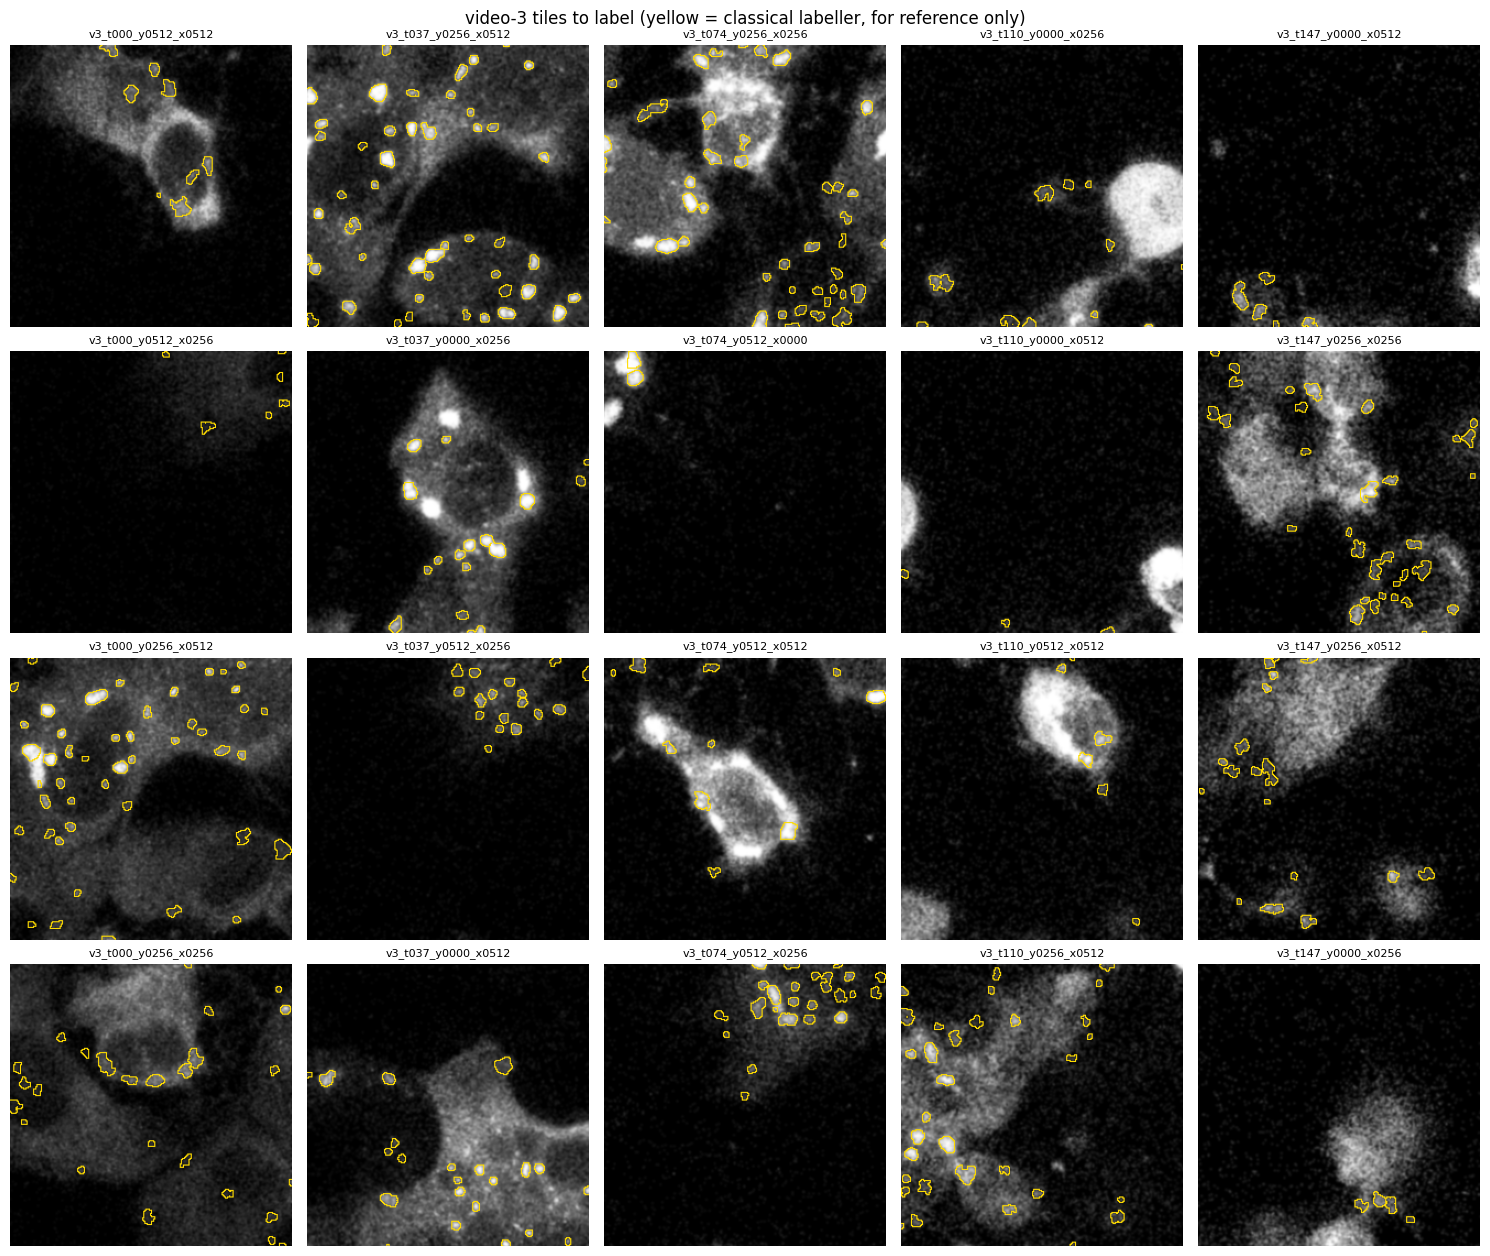

In [14]:
if 'v3' not in PRE:
    print('Video 3 was not found - set V3_PATTERN in the config cell and re-run.')
else:
    LOCAL_RF = '/content/roboflow_v3'
    RF = SH.export_label_tiles(PRE['v3'], PLB['v3'], 'v3', range(SKIP_FIRST.get('v3', 0), len(PRE['v3']['reg'])),
                               LOCAL_RF, n_frames=RF_FRAMES, per_frame=RF_PER_FRAME)
    if os.path.exists(RF_DIR):
        shutil.rmtree(RF_DIR)
    shutil.copytree(LOCAL_RF, RF_DIR)
    drive.flush_and_unmount(); drive.mount('/content/drive')
    ok = all(SH.sha256(os.path.join(LOCAL_RF, 'images', n + '.png')) == SH.sha256(os.path.join(RF_DIR, 'images', n + '.png')) for n in RF.name)
    print(RF.to_string(index=False))
    print('\n%d tiles, %d different grid positions, copies in Drive %s' % (len(RF), len(set(zip(RF.y, RF.x))), 'verified' if ok else 'DAMAGED - re-run'))
    print('Upload this to Roboflow:', os.path.join(RF_DIR, 'images.zip'))
    cols = 5; rows = int(np.ceil(len(RF) / cols))
    fig, ax = plt.subplots(rows, cols, figsize=(3 * cols, 3.2 * rows))
    for a in ax.ravel(): a.axis('off')
    for a, n in zip(ax.ravel(), RF.name):
        img = cv2.imread(os.path.join(LOCAL_RF, 'images', n + '.png'), 0)
        m = cv2.imread(os.path.join(LOCAL_RF, 'pseudo_masks', n + '.png'), 0)
        rgb = np.dstack([img] * 3); rgb[(cv2.dilate(m, np.ones((3, 3), np.uint8)) > 0) & (m == 0)] = (255, 220, 0)
        a.imshow(rgb); a.set_title(n, fontsize=8)
    fig.suptitle('video-3 tiles to label (yellow = classical labeller, for reference only)'); plt.tight_layout(); plt.show()

## Done
* Send **`SGTracking_5FOLD/DATA_FOR_TEAM_5FOLD/`** to the team; they run `python verify_download.py` inside it (must print `ALL FILES COMPLETE`). Tell them to delete the older 2-fold `DATA_FOR_TEAM`.
* Label **`SGTracking_5FOLD/ROBOFLOW_V3/images.zip`** in Roboflow: a polygon around every granule; export **COCO Segmentation**, no resize, file names unchanged. Keep `pseudo_masks/` and `tiles.csv` — they are needed for scoring.